6 Steps to build a Linear Regression model

Step 1: Importing the dataset

Step 2: Data pre-processing

Step 3: Splitting the test and train sets

Step 4: Fitting the linear regression mode to the training set

Step 5: Predicting test results

Step 6: Visualizing the test results

Step 7: Evaluation


In [ ]:
#1. IMPORTING LIBRARIES & LOADING DATASET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check if housing.csv exists, and if not, download a common version
import os
if not os.path.exists('housing.csv'):
  print ('Downloading housing.csv...')
  !wget -q https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv
  print('Download Complete')

dataset = pd.read_csv('housing.csv')
dataset.head()
dataset

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [ ]:
# 1.1. Print or displat the attributes of your dataset, look for missing values and check for data types
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
# 1.2. Print relevant statistical summary from your dataset
dataset.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


                    longitude  latitude  housing_median_age  total_rooms  \
longitude            1.000000 -0.924664           -0.108197     0.044568   
latitude            -0.924664  1.000000            0.011173    -0.036100   
housing_median_age  -0.108197  0.011173            1.000000    -0.361262   
total_rooms          0.044568 -0.036100           -0.361262     1.000000   
total_bedrooms       0.069608 -0.066983           -0.320451     0.930380   
population           0.099773 -0.108785           -0.296244     0.857126   
households           0.055310 -0.071035           -0.302916     0.918484   
median_income       -0.015176 -0.079809           -0.119034     0.198050   
median_house_value  -0.045967 -0.144160            0.105623     0.134153   

                    total_bedrooms  population  households  median_income  \
longitude                 0.069608    0.099773    0.055310      -0.015176   
latitude                 -0.066983   -0.108785   -0.071035      -0.079809   
housing_

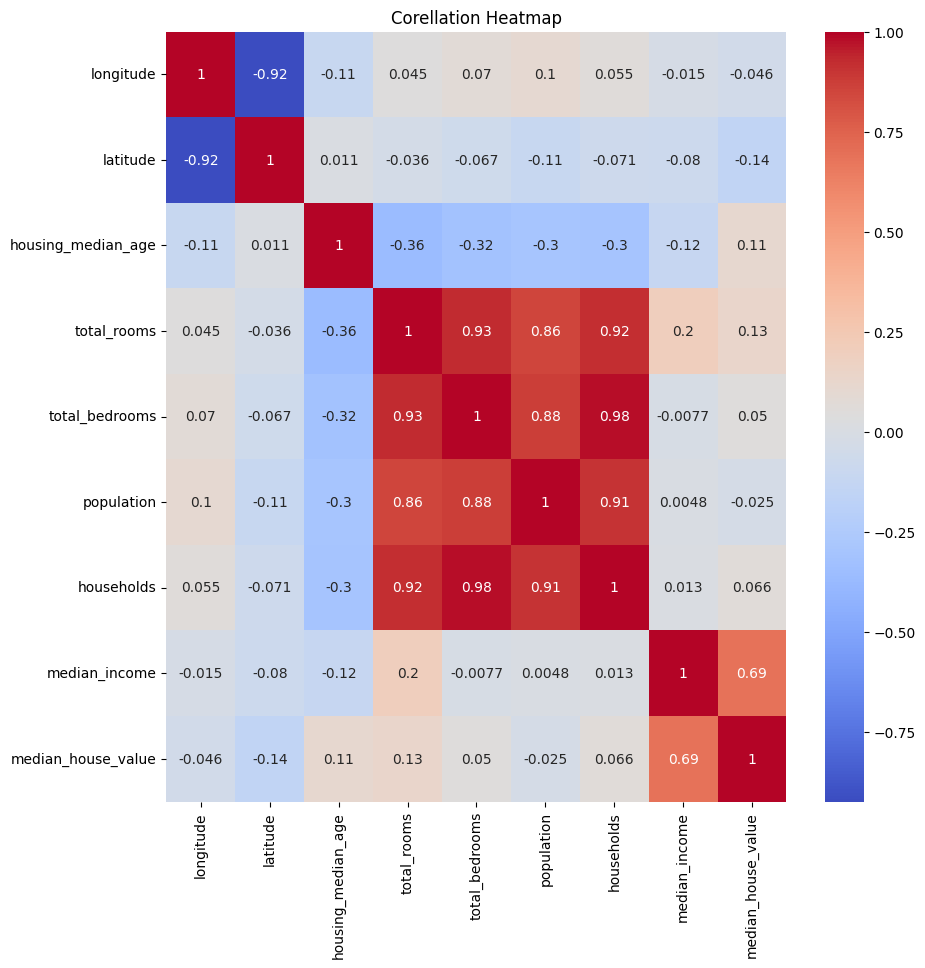

In [ ]:
# Display correlation between attributes
import seaborn as sns

correlation = dataset.drop('ocean_proximity', axis = 1).corr(method = 'pearson')
print(correlation)

plt.figure(figsize = (10, 10))
sns.heatmap(correlation, annot = True, cmap = 'coolwarm')
plt.title('Corellation Heatmap')
plt.show()

In [ ]:
# Convert ocean_proximity to numerical data
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
dataset['ocean_proximity'] = le.fit_transform(dataset['ocean_proximity'])
dataset.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,3
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,3
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,3
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,3
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,3


                    longitude  latitude  housing_median_age  total_rooms  \
longitude            1.000000 -0.924664           -0.108197     0.044568   
latitude            -0.924664  1.000000            0.011173    -0.036100   
housing_median_age  -0.108197  0.011173            1.000000    -0.361262   
total_rooms          0.044568 -0.036100           -0.361262     1.000000   
total_bedrooms       0.069608 -0.066983           -0.320451     0.930380   
population           0.099773 -0.108785           -0.296244     0.857126   
households           0.055310 -0.071035           -0.302916     0.918484   
median_income       -0.015176 -0.079809           -0.119034     0.198050   
median_house_value  -0.045967 -0.144160            0.105623     0.134153   
ocean_proximity     -0.289779  0.200974            0.112468    -0.015693   

                    total_bedrooms  population  households  median_income  \
longitude                 0.069608    0.099773    0.055310      -0.015176   
latitude 

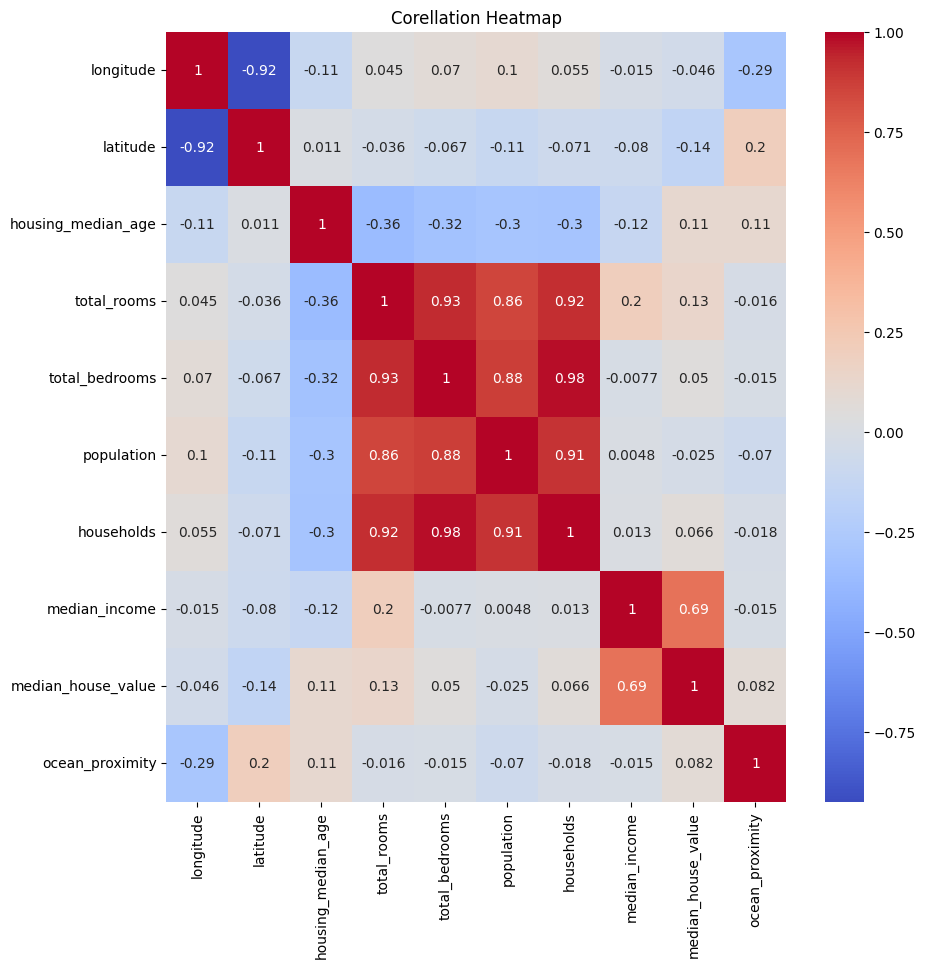

In [ ]:
# 1.3. Display the correlation heatmap
import seaborn as sns

correlations = dataset.corr(method = 'pearson')
print(correlations)

plt.figure(figsize = (10, 10))
sns.heatmap(correlations, annot = True, cmap = 'coolwarm')
plt.title('Corellation Heatmap')
plt.show()

The correlation heatmap shows the relationship between the attributes. We first converted the ocean_proximity to numerical data using label encorder to observe its relationship.

- The attributes *households* and *total_bedrooms* shows the greatest relationship of a **Strong Positive Correlation** of **0.98**.
- The attributes *total_bedrooms* and *total_rooms* shows the second greatest relationship of **Strong Positive Correlation** of **0.93**.
- The attributes *households* and *total_rooms* shows the third greatest relationship of **Strong Positive Correlation** of **0.92**.
- The attributes *population* and *total_bedrooms* shows the fourth greatest relationship of **Strong Positive Correlation** of **0.88**.
- The attributes *population* and *total_rooms* shows the fifth greatest relationship of **Strong Positive Correlation** of **0.86**.
- The attributes *median_income* and *median_house_value* shows the sixth greatest relationship is almost over **Weak Positive Correlation** of **0.69**.

Upon further observation, the correlation shows that the increases in one of the attributes aforementioned causes the increase of their corresponding correlating attribute.

Moreover, most of the correlation between variables lie between Weak Positive and Weak Negative Correlation, further indiciating that they do not have any significant correlation between them. The attributes showing Strong Positive Correlation could possibly indicate that they are the most significant features for extraction.

In [ ]:
# 2. DATA PREPROCESSING
from sklearn.impute import SimpleImputer

# 2.1 Define the target variable y (median_house_value)
Y = dataset['median_house_value'].values

# 2.2 Define the independent variables X
# Exclude 'median_house_value' (target) and 'ocean_proximity' (categorical) from X
X_numerical = dataset.drop(['median_house_value', 'ocean_proximity'], axis = 1)

# 2.3 Handle missing values in X_numerical using median imputation
imputer = SimpleImputer(strategy = 'median')
X = imputer.fit_transform(X_numerical)

# X is independent variable array and y is the dependent variable vector
# Note the difference between the arrray and vector
# The dependent variable must be in vector and independent variable must be an array itself

print(X)

[[-1.2223e+02  3.7880e+01  4.1000e+01 ...  3.2200e+02  1.2600e+02
   8.3252e+00]
 [-1.2222e+02  3.7860e+01  2.1000e+01 ...  2.4010e+03  1.1380e+03
   8.3014e+00]
 [-1.2224e+02  3.7850e+01  5.2000e+01 ...  4.9600e+02  1.7700e+02
   7.2574e+00]
 ...
 [-1.2122e+02  3.9430e+01  1.7000e+01 ...  1.0070e+03  4.3300e+02
   1.7000e+00]
 [-1.2132e+02  3.9430e+01  1.8000e+01 ...  7.4100e+02  3.4900e+02
   1.8672e+00]
 [-1.2124e+02  3.9370e+01  1.6000e+01 ...  1.3870e+03  5.3000e+02
   2.3886e+00]]


In [ ]:
# Convert the NumPy array X back to a pandas DataFrame and verify for missing values
X_df = pd.DataFrame(X, columns = X_numerical.columns)
X_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


In [ ]:
X_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100


In [ ]:
# DATA PREPROCESSING
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range = (0, 1))
rescaledX = scaler.fit_transform(X)

print(rescaledX)

[[0.21115538 0.5674814  0.78431373 ... 0.00894083 0.02055583 0.53966842]
 [0.21215139 0.565356   0.39215686 ... 0.0672104  0.18697583 0.53802706]
 [0.21015936 0.5642933  1.         ... 0.01381765 0.02894261 0.46602805]
 ...
 [0.31175299 0.73219979 0.31372549 ... 0.0281398  0.07104095 0.08276438]
 [0.30179283 0.73219979 0.33333333 ... 0.02068444 0.05722743 0.09429525]
 [0.30976096 0.72582359 0.29411765 ... 0.03879032 0.08699227 0.13025338]]


In [ ]:
# SPLITTING THE DATASET
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(rescaledX, Y, test_size = 0.30, random_state = 42)

In [ ]:
# 4. Fitting LInear Regression Model into the Training Set

from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

In [ ]:
# 4.1. Print Linear Regression Coefficient, y = b0 + b1x1

pd.DataFrame(regressor.coef_)

,0
0,-4.281359e+05
1,-3.981451e+05
2,6.044332e+04
3,-3.167047e+05
4,7.701477e+05
5,-1.340274e+06
6,2.414294e+05
7,5.852430e+05


In [ ]:
# 5. Predicting the Test Set Results

y_pred = regressor.predict(X_test)
print(y_pred)

[ 64628.40149728 153831.7442614  250210.62905939 ... 283790.08706491
 128164.26276147 213772.09884699]


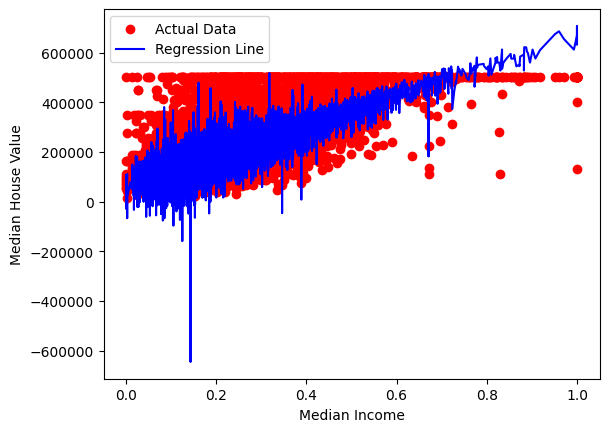

In [ ]:
# 6. Visualizing the Test Results

# Plot for the TRAIN

# Select the 'median_income' feature for visualization (it's at index 7 in X_train)
X_train_median_income = X_train[:, 7]

# Create an array of predictions for the training set
y_train_pred = regressor.predict(X_train)

# Create a DataFrame to sort both X_train_median_income and y_train_repd simulatenously for coherent plotting
plot_data = pd.DataFrame({'median_income': X_train_median_income, 'predictions': y_train_pred})
plot_data_sorted = plot_data.sort_values(by = 'median_income')

# Plot as a Scatter Plot
plt.scatter(X_train_median_income, y_train, color = 'red', label = 'Actual Data')
# plot_scatter = plot_data_sorted.plot(kind = 'scatter', x = 'median_income', y = 'predictions', figsize = (10, 7))

plt.plot(plot_data_sorted['median_income'], plot_data_sorted['predictions'], color = 'blue', label = 'Regression Line')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.legend()
plt.show()

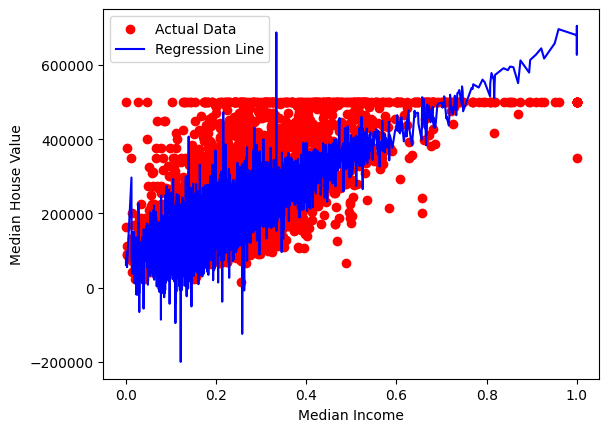

In [ ]:
# 6. Visualizing the Test Results

# Plot for the TEST

# Select the 'median_income' feature for visualization (it's at index 7 in X_train)
X_test_median_income = X_test[:, 7]

# Create an array of predictions for the training set
y_train_pred = regressor.predict(X_train)

# Create a DataFrame to sort both X_train_median_income and y_train_repd simulatenously for coherent plotting
plot_data_test = pd.DataFrame({'median_income': X_test_median_income, 'predictions': y_pred})
plot_data_test_sorted = plot_data_test.sort_values(by = 'median_income')

# Plot as a Scatter Plot
plt.scatter(X_test_median_income, y_test, color = 'red', label = 'Actual Data')
# plot_scatter = plot_data_sorted.plot(kind = 'scatter', x = 'median_income', y = 'predictions', figsize = (10, 7))

plt.plot(plot_data_test_sorted['median_income'], plot_data_test_sorted['predictions'], color = 'blue', label = 'Regression Line Test Predictions')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.legend()
plt.show()

In [ ]:
# Residuals - Difference between the predicted vs. the actual

# Compute for Residuals

y_pred2 = regressor.predict(rescaledX)
y_pred

array([ 64628.40149728, 153831.7442614 , 250210.62905939, ...,
       283790.08706491, 128164.26276147, 213772.09884699])

In [ ]:
dataset['Predicted House Value'] = y_pred2
dataset.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,Predicted House Value
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,411461.239483
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,415970.012294
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,381146.914684
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,322689.742997
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,254024.870255


In [ ]:
# Display actual median_house_value and predicted house value

actual_predicted = pd.DataFrame({'Actual_Median_House_Value': y_test, 'Predicted House Value': y_pred})
display(actual_predicted)

,Actual_Median_House_Value,Predicted House Value
0,47700.0,64628.401497
1,45800.0,153831.744261
2,500001.0,250210.629059
3,218600.0,263003.193676
4,278000.0,266892.049670
...,...,...
6187,237500.0,217372.089845
6188,67300.0,84022.216060
6189,218400.0,283790.087065
6190,119400.0,128164.262761


In [ ]:
# Evaluate the performance of the model using MEAN SQUARED ERROR and MEAN ABSOLUTE ERROR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'Mean Absolute Error: {mae}')
print(f'R-squared: {r2}')

Mean Squared Error: 4856976755.91279
Mean Absolute Error: 51048.951982172606
R-squared: 0.6299559360511687


In [ ]:
# Evaluate the performance of the model using MEAN SQUARED ERROR and MEAN ABSOLUTE ERROR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

print('mse =',  mean_squared_error(y_test, y_pred))
print('mae =', mean_absolute_error(y_test, y_pred))
print('r2 =', r2_score(y_test, y_pred))

# RESIDUAL = ACTUAL - PREDICTED

mse = 4856976755.91279
mae = 51048.951982172606
r2 = 0.6299559360511687


In [ ]:
# Assignment: Apply other preprocessing methods
# What if we convert the categorical data
# Compare the MAE, MSE, and R2_Score